<a id="sec-0"></a>
# Risk Parity + Trend — backtest notebook for the investor prospectus

**Financial Modeling (Nova SBE) · Group project · Moodle group: Group Z**

| Member | Student number |
|---|---|
| Gabriel Depraz | XXXXX |
| Marwan El-shazly | XXXXX |
| Bruno Francisco Barth | 79727 |
| Tim Jonas Trompa | 64287 |
| Paul Kuehl | 64253 |
| Felix Schoenstein | 80555 |

**Interactive app (Streamlit):** https://groupz-risk-parity-trend.streamlit.app
**Source code (GitHub):** https://github.com/paul2108/04_Financial-Modelin-Group-projects

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/paul2108/04_Financial-Modelin-Group-projects/blob/main/notebook/GroupZ_RiskParity_Trend.ipynb)

This notebook reproduces **every number, table and figure** in the prospectus
*“Risk Parity + Trend: a lower-drawdown alternative to the 60/40 portfolio”*.
It follows a standard **ETL** structure:

| Step | Section | What happens |
|---|---|---|
| Extract | [1](#sec-1) | daily prices are fetched from Yahoo Finance through the `yfinance` API (no data files) |
| Transform | [2](#sec-2) | cleaning, month-end sampling, returns, risk-free rate |
| Load | [3](#sec-3) | one aligned `MarketData` object that every later step reads |
| Analysis | [4](#sec-4)–[8](#sec-8) | strategy engine, benchmarks, performance, verification, robustness |
| Export | [9](#sec-9) | figures, tables and the number register used by the LaTeX prospectus |

### How to run
* **Google Colab:** open the notebook (badge above) and choose *Runtime → Run all*.
  The first cell installs `quantstats` (not pre-installed on Colab) and a current `yfinance`.
  A full run takes about 2–3 minutes.
* **Locally:** `make venv` and then `make notebook` in the repository (see `README.md`).
  Only a local run writes the export files for the prospectus.

Yahoo Finance revises adjusted prices from time to time (e.g. when dividends are re-booked).
A re-run may therefore differ from the prospectus in the last decimal. The data fingerprint in
[Section 2](#sec-2) and the retrieval time stamp in the number register document the exact data vintage.

<a id="sec-0-1"></a>
## 0.1 Setup

In [1]:
# Install packages that Google Colab does not ship (quantstats) and make sure yfinance is current.
# Locally the project's .venv already contains everything (see requirements.txt).
IN_COLAB = "google.colab" in str(get_ipython())   # IPython built-in: no import needed before the import cell
if IN_COLAB:
    !pip -q install "quantstats==0.0.86" "yfinance>=1.8"

In [2]:
# Import packages: every package used in this notebook is imported here, once.
# Mandatory packages of the assignment
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import fsolve
import yfinance as yf
import pandas as pd
import quantstats as qs

# Additional packages: statsmodels (Newey-West t-statistics) and the standard library
import statsmodels.api as sm
import json
import platform
import time
import warnings
from dataclasses import dataclass
from pathlib import Path

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning, module="quantstats")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)

# Versions used for this run (table)
for name, mod in [("python", platform), ("numpy", np), ("pandas", pd), ("yfinance", yf),
                  ("quantstats", qs), ("statsmodels", sm)]:
    version = platform.python_version() if name == "python" else mod.__version__
    print(f"{name:<12}{version}")

python      3.12.16
numpy       2.5.5
pandas      3.1.1
yfinance    1.8.0
quantstats  0.0.86
statsmodels 0.15.0


<a id="sec-0-2"></a>
## 0.2 Parameters

All assumptions of the backtest sit in this one cell. The **sample period is set explicitly**:
daily data from `START` up to (but excluding) `END`. yfinance treats `end` as exclusive, so the last
month in the sample is October 2026. The strategy parameters are fixed **in advance** from the
literature: Faber's (2007) 10-month moving average and a standard one-year (252 trading days) risk estimate.
They are not tuned on this sample. [Section 8](#sec-8) shows how sensitive the results are to them.

In [3]:
# ---------------------------------------------------------------- parameters
START = "2006-01-01"              # first day of daily data (inclusive)
END = "2026-11-01"                # last day of daily data (exclusive) -> last month = Oct 2026

RISKY_ASSETS = ["SPY", "EFA", "IEF", "VNQ", "DBC", "GLD"]   # the six asset classes held
BENCHMARK_6040 = {"SPY": 0.60, "AGG": 0.40}                  # balanced benchmark (investable)
MARKET = "^SP500TR"               # S&P 500 total return index: market proxy for CAPM alpha/beta
RF_TICKER = "^IRX"                # 13-week US T-bill yield (% p.a.): risk-free rate and cash return
OTHER_TICKERS = ["AGG", MARKET]   # benchmark building blocks that the strategy does not hold
ALL_TICKERS = RISKY_ASSETS + OTHER_TICKERS + [RF_TICKER]

COV_WINDOW = 252                  # trading days used to estimate the covariance matrix
SMA_WINDOW = 10                   # months in the trend filter's moving average (Faber, 2007)
COST_BPS = 10.0                   # transaction cost in basis points per unit of turnover
WEIGHTING = "erc"                 # "erc" (equal risk contribution), "inverse_vol" or "equal"
NW_LAGS = 4                       # Newey-West lags for the t-statistic of alpha
PERIODS = 12                      # monthly data -> 12 periods per year

ASSET_NAMES = {
    "SPY": "US equities (S&P 500)",
    "EFA": "Developed ex-US equities",
    "IEF": "US Treasuries 7-10y",
    "VNQ": "US real estate (REITs)",
    "DBC": "Broad commodities",
    "GLD": "Gold",
    "CASH": "T-bills (cash)",
    "AGG": "US aggregate bonds",
    "^SP500TR": "S&P 500 total return",
}

REPO_URL = "https://github.com/paul2108/04_Financial-Modelin-Group-projects"
APP_URL = "https://groupz-risk-parity-trend.streamlit.app"
NOTEBOOK_VIEW_URL = ("https://nbviewer.org/github/paul2108/04_Financial-Modelin-Group-projects/"
                     "blob/main/notebook/GroupZ_RiskParity_Trend.ipynb")

<a id="sec-0-3"></a>
## 0.3 Helpers: number register and chart style

The prospectus does not contain a single hand-typed result. Every number, table and figure it
shows is **registered** here when it is computed. Each entry records:
* the value,
* a description,
* the notebook section that produced it,
* the data source (API and tickers),
* the time the data was retrieved.

[Section 9](#sec-9) prints the full register and exports it as `results_macros.tex`. In LaTeX the
command `\res{key}` prints the value and links it to the *Sources of figures* table in the appendix.

In [4]:
REGISTER = []   # filled while the notebook runs, exported in Section 9


def fmt_value(value, kind):
    """Return (plain text, LaTeX) representations of a result."""
    if kind == "pct1":      # 0.0734 -> 7.3%
        txt = f"{100 * value:.1f}%"
    elif kind == "pct2":
        txt = f"{100 * value:.2f}%"
    elif kind == "pp1":     # percentage points
        txt = f"{100 * value:.1f} pp"
    elif kind == "num2":
        txt = f"{value:.2f}"
    elif kind == "num1":
        txt = f"{value:.1f}"
    elif kind == "x2":      # growth multiple
        txt = f"{value:.2f}x"
    elif kind == "bps0":
        txt = f"{value:.0f} bps"
    elif kind == "int":
        txt = f"{int(value):,}"
    elif kind == "date":
        txt = pd.Timestamp(value).strftime("%b %Y")
    elif kind == "day":
        txt = pd.Timestamp(value).strftime("%d %b %Y")
    else:                   # free text
        txt = str(value)
    tex = (txt.replace("%", r"\%").replace("x", r"$\times$") if kind == "x2" else txt.replace("%", r"\%"))
    if txt.startswith("-"):
        tex = "$-$" + tex[1:]
    return txt, tex


def register(key, value, kind, description, section, sources):
    """Store a result for the prospectus. `section` is e.g. '6.1'; `sources` lists the tickers used."""
    txt, tex = fmt_value(value, kind)
    entry = dict(key=key, value=txt, tex=tex, raw=value if np.isscalar(value) else str(value),
                 description=description, section=section, sources=list(sources))
    REGISTER[:] = [e for e in REGISTER if e["key"] != key] + [entry]
    return txt


def register_item(key, label_tex, description, section, sources):
    """Register a figure or table (its 'value' is the LaTeX cross-reference, e.g. Fig.~\\ref{fig:cum})."""
    entry = dict(key=key, value=description, tex=label_tex, raw=None,
                 description=description, section=section, sources=list(sources))
    REGISTER[:] = [e for e in REGISTER if e["key"] != key] + [entry]


# --- chart style (validated categorical palette, legends below the plot, recessive grid) ----------
COLORS = {"Strategy": "#2a78d6", "60/40": "#eb6834", "S&P 500 TR": "#1baf7a",
          "ERC (no trend)": "#eda100", "1/N (no trend)": "#6250d6"}
ASSET_COLORS = {"SPY": "#2a78d6", "EFA": "#eb6834", "IEF": "#1baf7a", "VNQ": "#eda100",
                "DBC": "#e87ba4", "GLD": "#008300", "CASH": "#c3c2b7"}
INK, INK_2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "font.size": 9, "axes.titlesize": 10,
    "axes.labelsize": 9, "axes.edgecolor": INK_2, "axes.labelcolor": INK, "xtick.color": INK_2,
    "ytick.color": INK_2, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
    "lines.linewidth": 1.6, "font.family": "DejaVu Sans", "xtick.labelsize": 8, "ytick.labelsize": 8,
    "legend.fontsize": 8, "figure.constrained_layout.use": False,
})
FIG_W = 6.77  # inches = text width of the prospectus (A4, 1.9 cm margins)


def legend_below(fig, ax, ncol=4):
    """Legend centred below the plot (figures use layout="constrained")."""
    handles, labels = ax.get_legend_handles_labels()
    fig.legend(handles, labels, loc="outside lower center", ncol=ncol, frameon=False)


# --- export targets: only a local run inside the repository writes files for the prospectus -------
NB_DIR = Path.cwd()
REPO_ROOT = next((p for p in [NB_DIR, *NB_DIR.parents]
                  if (p / "prospectus").is_dir() and (p / "app").is_dir()), None)
EXPORT = (not IN_COLAB) and REPO_ROOT is not None
if EXPORT:
    FIG_DIR, TAB_DIR = REPO_ROOT / "prospectus" / "figures", REPO_ROOT / "prospectus" / "tables"
    FIG_DIR.mkdir(parents=True, exist_ok=True)
    TAB_DIR.mkdir(parents=True, exist_ok=True)
print("Export to prospectus:", f"yes -> {REPO_ROOT}" if EXPORT else "no (Colab or outside the repository)")


def save_figure(fig, name):
    if EXPORT:
        fig.savefig(FIG_DIR / f"{name}.pdf", bbox_inches="tight")


def save_table(tex, name):
    if EXPORT:
        (TAB_DIR / f"{name}.tex").write_text(tex, encoding="utf-8")

Export to prospectus: yes -> /Users/paulkuehl/Documents/GitHub/04_Financial-Modeling


<a id="sec-1"></a>
## 1 Extract — daily prices from the Yahoo Finance API

**Source:** Yahoo Finance, accessed through the open-source `yfinance` package (one batched request).

**Instruments:**
* the six ETFs the strategy holds,
* `AGG` for the bond leg of the 60/40 benchmark,
* the S&P 500 total-return index `^SP500TR` (CAPM market proxy),
* the 13-week T-bill yield `^IRX` (risk-free rate).

**Adjustment:** `auto_adjust=True` returns close prices adjusted for splits **and** distributions.
Returns computed from them are therefore total returns, net of each ETF's expense ratio, which is
already deducted from the fund's NAV.

**Frequency:** daily. Month-end values are derived in [Section 2](#sec-2).

In [5]:
# ---------------------------------------------------------------- extract
def download_prices(tickers, start, end, retries=3, pause=5.0):
    """EXTRACT: daily split- and dividend-adjusted close prices from Yahoo Finance.

    One batched yfinance call (fewer requests -> fewer rate-limit problems); `end` is exclusive.
    The columns come back in the order of `tickers` (yfinance itself sorts them alphabetically).
    """
    tickers = list(tickers)
    last_error = None
    for attempt in range(1, retries + 1):
        try:
            raw = yf.download(tickers, start=start, end=end, interval="1d",
                              auto_adjust=True, progress=False, threads=True)
            if raw is not None and not raw.empty:
                close = raw["Close"]
                if isinstance(close, pd.Series):          # single ticker -> Series
                    close = close.to_frame(tickers[0])
                close = close.reindex(columns=tickers)
                missing = [t for t in tickers if close[t].notna().sum() == 0]
                if not missing:
                    return close
                last_error = RuntimeError(f"no data returned for {missing}")
        except Exception as exc:                          # network / rate-limit errors
            last_error = exc
        if attempt < retries:
            time.sleep(pause * attempt)
    raise RuntimeError(f"Download from Yahoo Finance failed after {retries} attempts: {last_error}")

In [6]:
DATA_RETRIEVED_UTC = pd.Timestamp.now(tz="UTC").floor("min")
prices_raw = download_prices(ALL_TICKERS, START, END)
RETRIEVED_TXT = DATA_RETRIEVED_UTC.strftime("%Y-%m-%d %H:%M UTC")
register("data_retrieved", RETRIEVED_TXT, "text", "Time stamp of the Yahoo Finance download", "1", ALL_TICKERS)

print(f"Retrieved {RETRIEVED_TXT}")
print("Raw shape (rows, columns):", prices_raw.shape)
print("Raw date range:", prices_raw.index.min().date(), "to", prices_raw.index.max().date())
prices_raw.tail(3)

Retrieved 2026-11-20 22:11 UTC
Raw shape (rows, columns): (5240, 9)
Raw date range: 2006-01-03 to 2026-10-30


Ticker,SPY,EFA,IEF,VNQ,DBC,GLD,AGG,^SP500TR,^IRX
Date,,,,,,,,,
2026-10-28,772.309998,103.680000,90.542084,91.790001,33.790001,373.510010,95.549667,17377.560547,3.995
2026-10-29,769.359985,104.349998,90.940727,93.870003,33.720001,368.570007,95.808746,17324.679688,3.998
2026-10-30,755.719971,103.370003,91.448997,93.940002,33.610001,355.779999,96.017998,17011.140625,3.973


In [7]:
# Raw-data checks: first available date and missing values per ticker
raw_check = pd.DataFrame({
    "first valid date": prices_raw.apply(lambda s: s.first_valid_index().date()),
    "last valid date": prices_raw.apply(lambda s: s.last_valid_index().date()),
    "non-missing days": prices_raw.notna().sum(),
    "missing days": prices_raw.isna().sum(),
})
raw_check

,first valid date,last valid date,non-missing days,missing days
Ticker,,,,
SPY,2006-01-03,2026-10-30,5240,0
EFA,2006-01-03,2026-10-30,5240,0
IEF,2006-01-03,2026-10-30,5240,0
VNQ,2006-01-03,2026-10-30,5240,0
DBC,2006-02-06,2026-10-30,5217,23
GLD,2006-01-03,2026-10-30,5240,0
AGG,2006-01-03,2026-10-30,5240,0
^SP500TR,2006-01-03,2026-10-30,5240,0
^IRX,2006-01-03,2026-10-30,5237,3


The late inception of **DBC (February 2006)** produces the missing days at the start of the sample.
All other tickers have only isolated gaps. These are mostly days on which an index (`^IRX`,
`^SP500TR`) and the ETFs do not quote at the same time. Nothing is filled at this stage.

<a id="sec-2"></a>
## 2 Transform — clean, sample at month-end, compute returns

| Step | Rule |
|---|---|
| Time zone | removed (`tz_localize(None)`) so that all series align on calendar dates |
| Duplicates | duplicate dates dropped, index sorted |
| Month-end sampling | last available daily close of each calendar month (`resample("ME").last()`). We do not use yfinance's `interval="1mo"`, whose bars are labelled at the start of the month and may include a partial month. |
| Returns | **simple** returns $R_t = P_t/P_{t-1}-1$. A portfolio's return is then exactly the weighted sum of its assets' returns, $R_{p,t}=\sum_i w_{i}R_{i,t}$. Log returns add up over time, but not across assets. |
| Daily returns for risk estimates | computed only on days on which all held ETFs trade. No price is filled forward. |
| Risk-free rate | `^IRX` is an annualised yield in percent. Monthly cash return in month $t$: $r_{f,t} = \text{IRX}_{t-1}/1200$, the yield observed at the end of the previous month. It is therefore known when the cash is invested. Isolated missing quotes are filled forward for at most 5 days. |

In [8]:
# ---------------------------------------------------------------- transform & load
@dataclass
class MarketData:
    """LOAD: the clean, aligned data that every later step reads."""
    prices_d: pd.DataFrame   # daily adjusted close prices (all tickers incl. ^IRX yield)
    rets_d: pd.DataFrame     # daily simple returns of the tradable tickers
    prices_m: pd.DataFrame   # month-end prices of the tradable tickers
    rets_m: pd.DataFrame     # monthly simple returns, labelled with the month they are earned in
    rf_m: pd.Series          # risk-free return earned in month t (known at the end of month t-1)


def clean_prices(raw):
    """TRANSFORM: tz-naive sorted daily index without duplicates or empty rows."""
    p = raw.copy()
    p.index = pd.to_datetime(p.index)
    if p.index.tz is not None:
        p.index = p.index.tz_localize(None)
    p = p[~p.index.duplicated(keep="last")].sort_index()
    return p.dropna(how="all")


def to_month_end(prices):
    """Last available daily observation of every calendar month (labelled with the month-end date)."""
    return prices.resample("ME").last()


def rf_from_irx(irx):
    """^IRX (13-week T-bill yield, % p.a.) -> monthly cash return earned in the FOLLOWING month."""
    irx_m = to_month_end(irx.ffill(limit=5))
    return (irx_m / 1200).shift(1).rename("rf")


def build_market_data(prices_raw, risky, others, rf_ticker="^IRX"):
    """TRANSFORM + LOAD: everything the strategy, benchmarks and metrics need."""
    p = clean_prices(prices_raw)
    tradables = list(risky) + list(others)
    prices_d = p[tradables + [rf_ticker]]
    rets_d = prices_d[tradables].pct_change(fill_method=None)
    prices_m = to_month_end(prices_d[tradables])
    rets_m = prices_m.pct_change(fill_method=None)
    rf_m = rf_from_irx(prices_d[rf_ticker]).reindex(prices_m.index)
    return MarketData(prices_d=prices_d, rets_d=rets_d, prices_m=prices_m, rets_m=rets_m, rf_m=rf_m)

In [9]:
data = build_market_data(prices_raw, RISKY_ASSETS, OTHER_TICKERS, RF_TICKER)

# The "four checks" of Lecture 3 on the transformed data: shape, date range, missing values, plot
print("Daily prices   :", data.prices_d.shape, data.prices_d.index.min().date(), "to", data.prices_d.index.max().date())
print("Month-end data :", data.prices_m.shape, data.prices_m.index.min().date(), "to", data.prices_m.index.max().date())
assert data.prices_m.index[-1] == pd.Timestamp("2026-10-31"), "last month must be October 2026"
assert data.prices_d.index[-1] <= pd.Timestamp("2026-10-31"), "no partial November data"
assert data.prices_m.index.is_month_end.all()
print("\nMissing month-end values per ticker (only before inception):")
print(data.prices_m.isna().sum().to_string())

Daily prices   : (5240, 9) 2006-01-03 to 2026-10-30
Month-end data : (250, 8) 2006-01-31 to 2026-10-31

Missing month-end values per ticker (only before inception):
Ticker
SPY         0
EFA         0
IEF         0
VNQ         0
DBC         1
GLD         0
AGG         0
^SP500TR    0


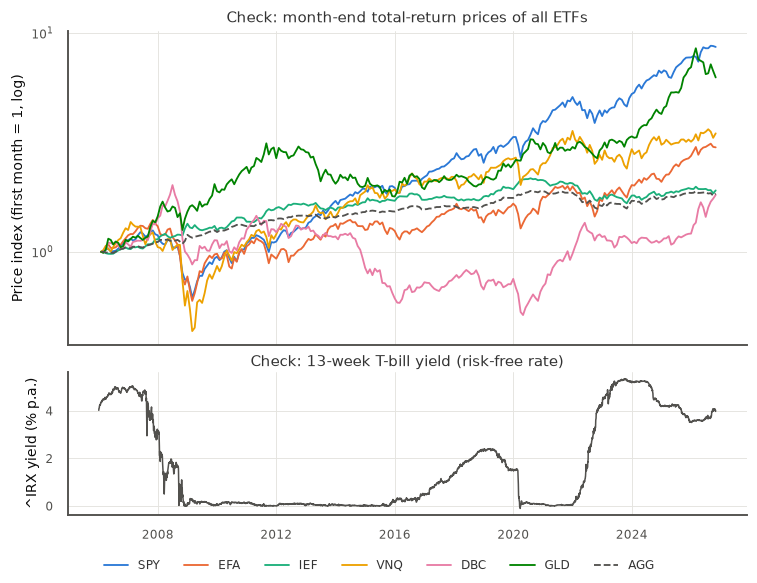

In [10]:
fig, axes = plt.subplots(2, 1, figsize=(FIG_W, 5.2), sharex=True, height_ratios=[2.2, 1], layout="constrained")
norm = data.prices_m[RISKY_ASSETS + ["AGG"]].apply(lambda s: s / s.dropna().iloc[0])
for col in RISKY_ASSETS + ["AGG"]:
    axes[0].plot(norm.index, norm[col], color=ASSET_COLORS.get(col, INK_2),
                 lw=1.2, label=col, ls="-" if col != "AGG" else "--")
axes[0].set_yscale("log")
axes[0].set_ylabel("Price index (first month = 1, log)")
axes[0].set_title("Check: month-end total-return prices of all ETFs")
legend_below(fig, axes[0], ncol=7)
axes[1].plot(data.prices_d.index, data.prices_d[RF_TICKER], color=INK_2, lw=1)
axes[1].set_ylabel("^IRX yield (% p.a.)")
axes[1].set_title("Check: 13-week T-bill yield (risk-free rate)", pad=4)
plt.show()

**Data fingerprint.** First and last observations of every series document the data vintage.
If Yahoo revises its history, this table changes and so would the results.

In [11]:
fingerprint = pd.DataFrame({
    "first date": data.prices_d.apply(lambda s: s.first_valid_index().date()),
    "first value": data.prices_d.apply(lambda s: s.dropna().iloc[0]).round(4),
    "last date": data.prices_d.apply(lambda s: s.last_valid_index().date()),
    "last value": data.prices_d.apply(lambda s: s.dropna().iloc[-1]).round(4),
    "daily obs": data.prices_d.notna().sum(),
})
fingerprint

,first date,first value,last date,last value,daily obs
Ticker,,,,,
SPY,2006-01-03,86.7854,2026-10-30,755.7200,5240
EFA,2006-01-03,33.6204,2026-10-30,103.3700,5240
IEF,2006-01-03,48.2562,2026-10-30,91.4490,5240
VNQ,2006-01-03,25.6024,2026-10-30,93.9400,5240
DBC,2006-02-06,19.1851,2026-10-30,33.6100,5217
GLD,2006-01-03,53.1200,2026-10-30,355.7800,5240
AGG,2006-01-03,52.0341,2026-10-30,96.0180,5240
^SP500TR,2006-01-03,1918.9600,2026-10-30,17011.1406,5240
^IRX,2006-01-03,4.0200,2026-10-30,3.9730,5237


<a id="sec-3"></a>
## 3 Load — the sample the analysis uses

The strategy can decide only once every input exists:
* 252 complete daily returns for the covariance matrix,
* 10 month-end prices for each moving average.

DBC, the youngest ETF, sets the start. **The first decision is taken at the close of
28 February 2007, and the first return is earned in March 2007.** Every strategy variant,
benchmark and robustness check uses exactly this window, so that all of them are evaluated
on the same months.

<a id="sec-4"></a>
## 4 Strategy engine

Every month-end $t$, at the closing price, the strategy takes three steps:

1. **Risk estimate.** Estimate the covariance matrix $\Sigma_t$ of the six ETFs from the last
   252 daily returns up to and including $t$.
2. **Risk parity.** Choose weights so that every asset class contributes the same share of
   portfolio risk (equal risk contribution, ERC; Maillard, Roncalli & Teïletche, 2010):
   $$RC_i = \frac{w_i(\Sigma w)_i}{w^\top\Sigma w} = \frac{1}{N}\qquad i=1,\dots,N .$$
   The weights have no closed form, so we solve the nonlinear system with **`scipy.optimize.fsolve`**.
   Following Spinu (2013), ERC holds exactly when $(\Sigma x)_i - \tfrac{1}{N x_i}=0$ for all $i$. These
   are the first-order conditions of a strictly convex problem, so the positive solution is unique.
   We solve them in log-coordinates $x=e^{y}$, which keeps every weight positive, and set
   $w=x/\sum_i x_i$. A test on 2,000 random covariance matrices converged every time.
   The starting value is the inverse-volatility portfolio. Every solution is checked: if the risk
   contributions are not equal to within $10^{-8}$, the month falls back to inverse-volatility
   weights and the fallback is counted.
3. **Trend filter.** An asset class is held only if its month-end price is above its 10-month
   simple moving average (Faber, 2007). Otherwise its risk-parity weight is moved into T-bills (cash).

The new weights earn the returns of month $t+1$: **decide at $t$, earn $t+1$** (the `shift(1)` rule
of Lecture 4). Between two rebalancing dates the holdings drift with prices. At each rebalancing,
the traded amount (turnover) is the distance between the target weights and the drifted weights:
$$TO_t=\sum_{i\in\text{ETFs}}\left|w_{i,t}-\tilde w_{i,t}\right|,\qquad
\tilde w_{i,t}=\frac{w_{i,t-1}(1+R_{i,t})}{1+R_{p,t}} .$$
Trading costs $c$ per unit of turnover reduce the portfolio value before the next month's return:
$V_{t+1}=V_t\,(1-c\cdot TO_t)\,(1+R_{p,t+1})$. Switching into and out of T-bills is assumed to be free,
as it is in a money-market sweep account.

In [12]:
# ---------------------------------------------------------------- strategy: risk parity weights
def inverse_vol_weights(cov):
    """Weights proportional to 1/volatility (the ERC solution when correlations are zero)."""
    iv = 1.0 / np.sqrt(np.diag(np.asarray(cov, dtype=float)))
    return iv / iv.sum()


def risk_contributions(w, cov):
    """Share of portfolio variance contributed by each asset (sums to 1)."""
    w = np.asarray(w, dtype=float)
    cov = np.asarray(cov, dtype=float)
    return w * (cov @ w) / (w @ cov @ w)


def erc_weights(cov, tol=1e-8):
    """Equal-risk-contribution weights, solved with scipy's fsolve (Spinu, 2013).

    ERC holds when x_i (S x)_i = 1/N for all i, i.e. when (S x)_i - 1/(N x_i) = 0: the first-order
    condition of the convex problem min 0.5 x'Sx - (1/N) sum(log x_i). We solve these N equations in
    log-coordinates x = exp(y) > 0, so the weights stay positive, and return w = x / sum(x).
    Returns (weights, ok). If the solution fails the check, inverse-vol weights are returned and ok=False.
    """
    cov = np.atleast_2d(np.asarray(cov, dtype=float))
    n = cov.shape[0]
    S = cov / np.mean(np.diag(cov))                 # rescale: the solution does not depend on the scale
    iv = 1.0 / np.sqrt(np.diag(S))
    x0 = iv / np.sqrt(iv @ S @ iv)                  # inverse-vol start, scaled so that x0' S x0 = 1

    def equations(y):
        x = np.exp(y)
        return S @ x - 1.0 / (n * x)

    def jacobian(y):                                # d equations_i / d y_j
        x = np.exp(y)
        return S * x[None, :] + np.diag(1.0 / (n * x))

    y, _info, ier, _msg = fsolve(equations, np.log(x0), fprime=jacobian, full_output=True, xtol=1e-12)
    w = np.exp(y)
    w = w / w.sum()
    ok = bool(ier == 1 and np.all(np.isfinite(w))
              and np.max(np.abs(risk_contributions(w, cov) - 1.0 / n)) < tol)
    if not ok:
        return inverse_vol_weights(cov), False
    return w, True

In [13]:
# ---------------------------------------------------------------- strategy: trend filter and target weights
def trend_signal(prices_m, window=10):
    """1.0 if the month-end price is above its `window`-month SMA (incl. the current month), 0.0 if not,
    NaN while the moving average is not yet available."""
    sma = prices_m.rolling(window, min_periods=window).mean()
    return (prices_m > sma).astype(float).where(sma.notna())


def first_decision_date(data, assets, cov_window=252, sma_window=10):
    """First month-end at which the covariance window and every moving average are complete."""
    assets = list(assets)
    px = data.prices_d[assets].dropna()
    first_cov = px.index[cov_window]                 # cov_window returns need cov_window + 1 prices
    first_sig = trend_signal(data.prices_m[assets], sma_window).dropna().index[0]
    months = data.prices_m.index
    return months[(months >= first_cov) & (months >= first_sig)][0]


def target_weights(data, assets, decision_dates, cov_window=252, sma_window=10,
                   use_trend=True, weighting="erc"):
    """Target weights decided at each month-end (rows) for the assets plus CASH (columns).

    Only information up to and including the decision date is used.
    """
    assets = list(assets)
    px = data.prices_d[assets].dropna()              # days on which all held ETFs trade
    rd = px.pct_change(fill_method=None).iloc[1:]
    sig = trend_signal(data.prices_m[assets], sma_window)
    rows, fallbacks = [], 0
    for t in decision_dates:
        window = rd.loc[:t].iloc[-cov_window:]
        if len(window) < cov_window:
            raise ValueError(f"{t.date()}: only {len(window)} daily returns available, need {cov_window}")
        cov = np.atleast_2d(np.cov(window.to_numpy(), rowvar=False))
        if weighting == "erc":
            w, ok = erc_weights(cov)
            fallbacks += int(not ok)
        elif weighting == "inverse_vol":
            w = inverse_vol_weights(cov)
        elif weighting == "equal":
            w = np.full(len(assets), 1.0 / len(assets))
        else:
            raise ValueError(f"unknown weighting '{weighting}'")
        w = pd.Series(w, index=assets, dtype=float)
        if use_trend:
            on = sig.loc[t, assets]
            if on.isna().any():
                raise ValueError(f"{t.date()}: trend signal not yet available")
            w = w.where(on == 1.0, 0.0)
        w["CASH"] = 1.0 - w.sum()
        rows.append(w.rename(t))
    W = pd.DataFrame(rows)
    W.index.name = "decision_date"
    W.attrs["fsolve_fallbacks"] = fallbacks
    return W


def constant_weights(weights, decision_dates):
    """Fixed-mix target weights (e.g. 60/40), rebalanced back to target at every decision date."""
    w = pd.Series(weights, dtype=float)
    if "CASH" not in w.index:
        w["CASH"] = 1.0 - w.sum()
    cols = [c for c in w.index if c != "CASH"] + ["CASH"]
    W = pd.DataFrame([w[cols].to_numpy()] * len(decision_dates),
                     index=pd.DatetimeIndex(decision_dates, name="decision_date"), columns=cols)
    W.attrs["fsolve_fallbacks"] = 0
    return W

In [14]:
# ---------------------------------------------------------------- backtest engine
def backtest(weights, data, cost_bps=10.0):
    """Monthly backtest: weights decided at month-end t earn the simple returns of month t+1.

    Holdings drift between rebalancing dates. Turnover = sum over ETFs of |target - drifted|.
    Costs = cost_bps/10,000 x turnover, deducted from portfolio value before the month's return.
    CASH earns the risk-free rate. Returns a DataFrame indexed by the month the return is earned in.
    """
    cols = list(weights.columns)
    assets = [c for c in cols if c != "CASH"]
    R = data.rets_m.reindex(columns=assets).copy()
    R["CASH"] = data.rf_m
    R = R[cols]
    months = data.rets_m.index
    drifted = pd.Series(0.0, index=cols)
    drifted["CASH"] = 1.0                            # the investor starts fully in cash
    rows = []
    for t, w in weights.iterrows():
        pos = months.get_loc(t)
        if pos + 1 >= len(months):                   # last decision: no next-month return yet
            break
        t_next = months[pos + 1]
        r = R.loc[t_next]
        if r[w > 0].isna().any():
            raise ValueError(f"missing return in {t_next.date()} for a held asset")
        r = r.fillna(0.0)
        turnover = float((w[assets] - drifted[assets]).abs().sum()) if assets else 0.0
        cost = cost_bps / 1e4 * turnover
        gross = float((w * r).sum())
        net = (1.0 - cost) * (1.0 + gross) - 1.0
        rows.append({"date": t_next, "gross": gross, "net": net, "turnover": turnover,
                     "cost": cost, "cash_weight": float(w["CASH"]), "rf": float(r["CASH"])})
        drifted = w * (1.0 + r) / (1.0 + gross)
    return pd.DataFrame(rows).set_index("date")

<a id="sec-4-4"></a>
### 4.4 Performance measures

All measures use **monthly simple returns** with `ddof=1`. $R$ is the strategy's net return, $R_f$ the
T-bill return, $R_b$ the 60/40 benchmark and $R_M$ the S&P 500 total return. The definitions are
those of Lecture 3 and the course formula sheet:

| Measure | Definition | Annualisation |
|---|---|---|
| Average return | $\bar R$ | $\times 12$ (arithmetic) |
| CAGR | $\left[\prod_t(1+R_t)\right]^{12/T}-1$ | geometric; it is lower than the arithmetic mean by roughly $\sigma^2/2$ |
| Volatility | $\sigma(R)$ | $\times\sqrt{12}$ |
| Sharpe ratio | $E(R-R_f)/\sigma(R-R_f)$ | $12/\sqrt{12}=\sqrt{12}$ |
| Beta | $\beta=\operatorname{cov}(R-R_f,R_M-R_f)/\operatorname{var}(R_M-R_f)$ | **not annualised** |
| Alpha (Jensen) | $\alpha=E[R-R_f]-\beta\,E[R_M-R_f]$, with a Newey-West (4 lags) $t$-statistic | $\times 12$ |
| Tracking error | $\sigma(R-R_b)$ | $\times\sqrt{12}$ |
| Information ratio | $E(R-R_b)/\sigma(R-R_b)$, the benchmark-mandate version of Lecture 3 | $12/\sqrt{12}$ |
| Maximum drawdown | $\min_t(V_t/\max_{s\le t}V_s-1)$, including the start value $V_0=1$ | – |
| Turnover | $\overline{TO}$, share of portfolio value traded | $\times 12$ (per year) |

Beta and alpha are computed against the market, the S&P 500 (CAPM), and against the 60/40 benchmark.

In [15]:
# ---------------------------------------------------------------- performance measures
def nav_from_returns(r, start=None):
    """Value of 1 invested at the decision date before the first return (the series starts at 1)."""
    r = r.dropna()
    if start is None:
        start = r.index[0] - pd.offsets.MonthEnd(1)
    nav = (1.0 + r).cumprod()
    return pd.concat([pd.Series([1.0], index=pd.DatetimeIndex([start])), nav]).rename(r.name)


def drawdown_series(r):
    nav = nav_from_returns(r)
    return nav / nav.cummax() - 1.0


def max_drawdown(r):
    return float(drawdown_series(r).min())


def capm_regression(excess, factor_excess, maxlags=4):
    """OLS of excess returns on factor excess returns -> (beta, monthly alpha, Newey-West t(alpha))."""
    df = pd.concat([excess, factor_excess], axis=1).dropna()
    X = sm.add_constant(df.iloc[:, 1].to_numpy())
    fit = sm.OLS(df.iloc[:, 0].to_numpy(), X).fit(cov_type="HAC", cov_kwds={"maxlags": maxlags})
    alpha, beta = fit.params
    return float(beta), float(alpha), float(fit.tvalues[0])


def performance_summary(r, rf, benchmark=None, market=None, turnover=None, periods=12, nw_lags=4):
    """All performance measures of the prospectus for one monthly return series."""
    r = r.dropna()
    rf = rf.reindex(r.index)
    ex = r - rf
    out = {
        "months": int(len(r)),
        "ann_mean": periods * r.mean(),
        "cagr": float(np.prod(1.0 + r) ** (periods / len(r)) - 1.0),
        "ann_vol": np.sqrt(periods) * r.std(ddof=1),
        "sharpe": periods * ex.mean() / (np.sqrt(periods) * ex.std(ddof=1)),
        "max_dd": max_drawdown(r),
        "worst_12m": float(((1.0 + r).rolling(12).apply(np.prod, raw=True) - 1.0).min()),
        "final_value": float(np.prod(1.0 + r)),
    }
    if market is not None:
        b, a, t = capm_regression(ex, market.reindex(r.index) - rf, nw_lags)
        out.update(beta_mkt=b, alpha_mkt=periods * a, alpha_mkt_t=t)
    if benchmark is not None:
        bench = benchmark.reindex(r.index)
        active = r - bench
        out["tracking_error"] = np.sqrt(periods) * active.std(ddof=1)
        out["info_ratio"] = (periods * active.mean() / out["tracking_error"]
                             if out["tracking_error"] > 0 else np.nan)
        b, a, t = capm_regression(ex, bench - rf, nw_lags)
        out.update(beta_bench=b, alpha_bench=periods * a, alpha_bench_t=t)
    if turnover is not None:
        out["turnover"] = periods * turnover.reindex(r.index).mean()
    return out


def breakeven_cost(diff, x0=10.0, max_bps=1000.0):
    """Cost level c (bps per unit turnover) with diff(c) = 0, solved with fsolve.

    `diff(c)` is e.g. Sharpe(strategy, c) - Sharpe(benchmark, c). Returns (c, ok); (nan, False) if the
    strategy is not ahead even at zero cost, so that no break-even exists.
    """
    if not diff(0.0) > 0:
        return np.nan, False
    sol, _info, ier, _msg = fsolve(lambda c: [diff(float(c[0]))], [x0], full_output=True)
    c = float(sol[0])
    ok = bool(ier == 1 and 0.0 <= c <= max_bps and abs(diff(c)) < 1e-8)
    return (c if ok else np.nan), ok

In [16]:
# ---------------------------------------------------------------- one call for notebook and app
def run_strategy(data, assets=None, cov_window=252, sma_window=10, use_trend=True, weighting="erc",
                 cost_bps=10.0, start_decision=None, end_decision=None, benchmark_weights=None):
    """Run the full strategy (and optionally a fixed-mix benchmark) over a common decision window."""
    assets = list(RISKY_ASSETS if assets is None else assets)
    if start_decision is None:
        start_decision = first_decision_date(data, assets, cov_window, sma_window)
    months = data.prices_m.index
    dates = months[months >= pd.Timestamp(start_decision)]
    if end_decision is not None:
        dates = dates[dates <= pd.Timestamp(end_decision)]
    W = target_weights(data, assets, dates, cov_window, sma_window, use_trend, weighting)
    res = backtest(W, data, cost_bps)
    out = {"weights": W, "result": res, "returns": res["net"].rename("Strategy"),
           "gross": res["gross"].rename("Strategy (gross)"), "start_decision": pd.Timestamp(dates[0]),
           "fsolve_fallbacks": W.attrs["fsolve_fallbacks"]}
    if benchmark_weights is not None:
        Wb = constant_weights(benchmark_weights, dates)
        resb = backtest(Wb, data, cost_bps)
        out["benchmark"] = resb["net"].rename("Benchmark")
        out["benchmark_result"] = resb
    return out

In [17]:
T0 = first_decision_date(data, RISKY_ASSETS, COV_WINDOW, SMA_WINDOW)
assert T0 == pd.Timestamp("2007-02-28"), T0
months_all = data.prices_m.index
DECISION_DATES = months_all[months_all >= T0]
RETURN_MONTHS = DECISION_DATES[1:]
N_MONTHS = len(RETURN_MONTHS)
print(f"First decision (rebalancing) date: {T0.date()}")
print(f"Return months: {RETURN_MONTHS[0]:%b %Y} - {RETURN_MONTHS[-1]:%b %Y} "
      f"= {N_MONTHS} months ({N_MONTHS / 12:.1f} years)")

YF_ALL = ALL_TICKERS
register("data_start", pd.Timestamp(START), "day", "First day of daily data requested", "0.2", YF_ALL)
register("data_end", data.prices_d.index[-1], "day", "Last trading day in the sample", "2", YF_ALL)
register("first_decision", T0, "day", "First rebalancing date (decision at the close)", "3", RISKY_ASSETS)
register("sample_start", RETURN_MONTHS[0], "date", "First month with a strategy return", "3", RISKY_ASSETS)
register("sample_end", RETURN_MONTHS[-1], "date", "Last month with a strategy return", "3", RISKY_ASSETS)
register("sample_months", N_MONTHS, "int", "Number of monthly returns in the backtest", "3", RISKY_ASSETS)
register("sample_years", N_MONTHS / 12, "num1", "Length of the backtest in years", "3", RISKY_ASSETS)
register("rf_mean", 12 * data.rf_m.loc[RETURN_MONTHS].mean(), "pct1",
         "Average T-bill rate p.a. over the backtest", "3", [RF_TICKER])

First decision (rebalancing) date: 2007-02-28
Return months: Mar 2007 - Oct 2026 = 236 months (19.7 years)


'1.5%'

<a id="sec-4-6"></a>
### 4.6 The portfolio today

The last decision date in the sample is 31 October 2026. Its weights form the portfolio a new client
would hold from November 2026. The table shows all three steps of the rule:
1. the risk-parity weights,
2. the equal risk contributions they produce,
3. the trend filter and the resulting holdings.

In [18]:
t_last = DECISION_DATES[-1]
px_last = data.prices_d[RISKY_ASSETS].dropna()
win_last = px_last.pct_change(fill_method=None).iloc[1:].loc[:t_last].iloc[-COV_WINDOW:]
cov_last = np.cov(win_last.to_numpy(), rowvar=False)
w_erc_last, ok_last = erc_weights(cov_last)
sig_last = trend_signal(data.prices_m[RISKY_ASSETS], SMA_WINDOW).loc[t_last]
W_last = target_weights(data, RISKY_ASSETS, [t_last], COV_WINDOW, SMA_WINDOW, True, WEIGHTING).iloc[0]
current = pd.DataFrame({
    "asset class": [ASSET_NAMES[a] for a in RISKY_ASSETS],
    "volatility p.a.": np.sqrt(252 * np.diag(cov_last)),
    "ERC weight": w_erc_last,
    "risk contribution": risk_contributions(w_erc_last, cov_last),
    "above 10m SMA": sig_last.map({1.0: "yes", 0.0: "no"}).to_numpy(),
    "final weight": W_last[RISKY_ASSETS].to_numpy(),
}, index=RISKY_ASSETS)
print(f"fsolve converged: {ok_last};  cash weight: {W_last['CASH']:.1%}")
current.style.format({"volatility p.a.": "{:.1%}", "ERC weight": "{:.1%}",
                      "risk contribution": "{:.1%}", "final weight": "{:.1%}"})

fsolve converged: True;  cash weight: 46.3%


,asset class,volatility p.a.,ERC weight,risk contribution,above 10m SMA,final weight
SPY,US equities (S&P 500),12.8%,13.2%,16.7%,yes,13.2%
EFA,Developed ex-US equities,15.9%,9.3%,16.7%,yes,9.3%
IEF,US Treasuries 7-10y,5.0%,41.2%,16.7%,no,0.0%
VNQ,US real estate (REITs),13.7%,14.0%,16.7%,yes,14.0%
DBC,Broad commodities,20.5%,17.1%,16.7%,yes,17.1%
GLD,Gold,28.6%,5.1%,16.7%,no,0.0%


In [19]:
register("current_date", t_last, "day", "Date of the current allocation", "4.6", RISKY_ASSETS)
register("n_above_trend", int((sig_last == 1.0).sum()), "int", "Asset classes above their 10-month SMA (Oct 2026)",
         "4.6", RISKY_ASSETS)
register("current_cash", W_last["CASH"], "pct1", "Current weight in T-bills (Oct 2026)", "4.6",
         RISKY_ASSETS)
for a in RISKY_ASSETS:
    register(f"current_erc_{a.lower()}", w_erc_last[RISKY_ASSETS.index(a)], "pct1",
             f"Current risk-parity weight of {a}", "4.6", RISKY_ASSETS)

<a id="sec-5"></a>
## 5 Benchmarks and comparison portfolios

| Portfolio | Role |
|---|---|
| **60/40** (60% SPY, 40% AGG, rebalanced monthly) | Main benchmark: the standard balanced mandate our clients would otherwise hold. It is investable and is run through the **same engine with the same cost** as the strategy, so we compare net with net. |
| **S&P 500 total return** (`^SP500TR`) | The market portfolio for CAPM beta and alpha. It is an index, so it has no fees or trading costs. |
| **ERC without trend filter** | Shows what the trend filter adds. |
| **1/N without trend filter** (equal weights) | The naive diversification benchmark of DeMiguel, Garlappi & Uppal (2009). It shows what risk parity adds. |

All portfolios use the same decision dates, from February 2007 to October 2026.

In [20]:
base = run_strategy(data, RISKY_ASSETS, COV_WINDOW, SMA_WINDOW, use_trend=True, weighting=WEIGHTING,
                    cost_bps=COST_BPS, start_decision=T0, benchmark_weights=BENCHMARK_6040)
erc_nt = run_strategy(data, RISKY_ASSETS, COV_WINDOW, SMA_WINDOW, use_trend=False, weighting="erc",
                      cost_bps=COST_BPS, start_decision=T0)
ew_nt = run_strategy(data, RISKY_ASSETS, COV_WINDOW, SMA_WINDOW, use_trend=False, weighting="equal",
                     cost_bps=COST_BPS, start_decision=T0)
assert base["fsolve_fallbacks"] == 0 and erc_nt["fsolve_fallbacks"] == 0

r_strat = base["returns"]
r_gross = base["gross"]
r_6040 = base["benchmark"].rename("60/40")
r_mkt = data.rets_m[MARKET].loc[r_strat.index].rename("S&P 500 TR")
rf = data.rf_m.loc[r_strat.index]
assert r_strat.index.equals(RETURN_MONTHS) and r_6040.index.equals(RETURN_MONTHS)

series = {"Strategy": r_strat, "Strategy (gross)": r_gross, "ERC (no trend)": erc_nt["returns"],
          "1/N (no trend)": ew_nt["returns"], "60/40": r_6040, "S&P 500 TR": r_mkt}
turnovers = {"Strategy": base["result"]["turnover"], "Strategy (gross)": base["result"]["turnover"],
             "ERC (no trend)": erc_nt["result"]["turnover"], "1/N (no trend)": ew_nt["result"]["turnover"],
             "60/40": base["benchmark_result"]["turnover"], "S&P 500 TR": None}
pd.DataFrame(series).head()

,Strategy,Strategy (gross),ERC (no trend),1/N (no trend),60/40,S&P 500 TR
2007-03-31,-0.000002,0.000999,-0.000002,0.001342,0.005167,0.011187
2007-04-30,0.013681,0.013753,0.013681,0.019087,0.028930,0.044298
2007-05-31,-0.003855,-0.003829,-0.003855,0.002380,0.016664,0.034893
2007-06-30,-0.013266,-0.013244,-0.013266,-0.020769,-0.010300,-0.016612
2007-07-31,-0.000633,0.000051,0.002463,-0.011944,-0.014498,-0.031006


<a id="sec-6"></a>
## 6 Results

<a id="sec-6-1"></a>
### 6.1 Performance table

All figures are net of 10 bps trading costs per unit of turnover. The only exception is the
*Strategy (gross)* column, which shows the strategy before costs.

In [21]:
perf = {}
for name, r in series.items():
    is_bench = name == "60/40"
    perf[name] = performance_summary(
        r, rf, benchmark=None if is_bench else r_6040, market=r_mkt,
        turnover=turnovers[name], periods=PERIODS, nw_lags=NW_LAGS)
    perf[name]["avg_cash"] = (base["result"]["cash_weight"].mean() if name.startswith("Strategy") else 0.0)
perf_df = pd.DataFrame(perf)

ROWS = [  # (key, label, kind)
    ("ann_mean", "Average return p.a.", "pct"), ("cagr", "CAGR", "pct"), ("ann_vol", "Volatility p.a.", "pct"),
    ("sharpe", "Sharpe ratio", "num"), ("max_dd", "Maximum drawdown", "pct"), ("worst_12m", "Worst 12 months", "pct"),
    ("beta_mkt", "Beta vs S&P 500", "num"), ("alpha_mkt", "Alpha vs S&P 500 p.a.", "pct"),
    ("alpha_mkt_t", "  t-stat (Newey-West)", "num"), ("beta_bench", "Beta vs 60/40", "num"),
    ("alpha_bench", "Alpha vs 60/40 p.a.", "pct"), ("alpha_bench_t", "  t-stat (Newey-West)", "num"),
    ("tracking_error", "Tracking error vs 60/40", "pct"), ("info_ratio", "Information ratio vs 60/40", "num"),
    ("turnover", "Turnover p.a.", "pct"), ("avg_cash", "Average T-bill weight", "pct"),
    ("final_value", "Final value of $1", "num"),
]
show = perf_df.loc[[k for k, _, _ in ROWS]].copy()
show.index = [lbl for _, lbl, _ in ROWS]
fmt = {lbl: ("{:.1%}" if kind == "pct" else "{:.2f}") for _, lbl, kind in ROWS}
show.T.style.format(fmt, na_rep="–").set_caption(
    f"Performance {RETURN_MONTHS[0]:%b %Y} - {RETURN_MONTHS[-1]:%b %Y}, monthly data, net of {COST_BPS:.0f} bps")

,Average return p.a.,CAGR,Volatility p.a.,Sharpe ratio,Maximum drawdown,Worst 12 months,Beta vs S&P 500,Alpha vs S&P 500 p.a.,t-stat (Newey-West),Beta vs 60/40,Alpha vs 60/40 p.a.,t-stat (Newey-West),Tracking error vs 60/40,Information ratio vs 60/40,Turnover p.a.,Average T-bill weight,Final value of $1
Strategy,4.6%,4.6%,4.7%,0.66,-5.7%,-5.7%,0.10,2.1%,2.10,0.19,1.8%,1.90,9.0%,-0.39,215.7%,31.6%,2.42
Strategy (gross),4.8%,4.8%,4.7%,0.71,-5.4%,-5.4%,0.10,2.3%,2.34,0.19,2.0%,2.14,9.0%,-0.36,215.7%,31.6%,2.52
ERC (no trend),5.4%,5.3%,7.1%,0.55,-16.0%,-13.4%,0.29,0.9%,0.68,0.53,0.4%,0.35,6.7%,-0.41,51.1%,0.0%,2.75
1/N (no trend),7.1%,6.7%,11.3%,0.50,-36.8%,-34.2%,0.61,-0.6%,-0.37,0.98,-0.9%,-0.58,5.8%,-0.18,37.5%,0.0%,3.55
60/40,8.1%,7.9%,9.9%,0.67,-32.3%,-27.7%,0.63,0.2%,0.43,–,–,–,–,–,24.4%,0.0%,4.47
S&P 500 TR,11.7%,11.0%,15.4%,0.66,-50.9%,-43.3%,1.00,-0.0%,-4.27,1.54,0.0%,0.04,6.0%,0.59,–,0.0%,7.82


In [22]:
def tex_num(x, kind, signed=False):
    """Number for a LaTeX table cell; percentages without the % sign (the unit is in the row label)."""
    if x is None or (isinstance(x, float) and not np.isfinite(x)):
        return "--"
    s = f"{100 * x:.1f}" if kind == "pct" else f"{x:.2f}"
    if signed and not s.startswith("-"):
        s = "+" + s
    return "$-$" + s[1:] if s.startswith("-") else s


def tex_escape(s):
    for a, b in [("\\", r"\textbackslash{}"), ("&", r"\&"), ("%", r"\%"), ("$", r"\$"), ("#", r"\#"),
                 ("_", r"\_"), ("^", r"\textasciicircum{}"), ("~", r"\textasciitilde{}")]:
        s = s.replace(a, b)
    return s


def fin_table(sections, columns, first_col=""):
    """Financial-modelling style LaTeX table: dark-blue header, light-blue section rows, black rules."""
    ncol = len(columns)
    head = " & ".join([rf"\textcolor{{white}}{{\textbf{{{first_col}}}}}"]
                      + [rf"\textcolor{{white}}{{\textbf{{{c}}}}}" for c in columns])
    # tabularx over the full text width: the label column stretches, the number columns stay right-aligned
    lines = [r"\begin{tabularx}{\textwidth}{@{}X" + "r" * ncol + "@{}}", r"\toprule", r"\rowcolor{fmdark}" + head + r" \\"]
    for title, rows in sections:
        if title:
            lines.append(rf"\rowcolor{{fmlight}}\multicolumn{{{ncol + 1}}}{{@{{}}l}}{{\textbf{{{title}}}}} \\")
        for label, cells in rows:
            lines.append(" & ".join([label] + list(cells)) + r" \\")
    lines += [r"\bottomrule", r"\end{tabularx}"]
    return "\n".join(lines) + "\n"


TABLE_COLS = ["Strategy", "Strategy (gross)", "ERC (no trend)", "1/N (no trend)", "60/40", "S&P 500 TR"]
TEX_COLS = ["Strategy", "Gross", "ERC", "1/N", "60/40", r"S\&P 500"]
GROUPS = [
    ("Return and risk", ["ann_mean", "cagr", "ann_vol", "sharpe", "max_dd", "worst_12m"]),
    ("Relative to the market (S\\&P 500 TR)", ["beta_mkt", "alpha_mkt", "alpha_mkt_t"]),
    ("Relative to the 60/40 benchmark", ["beta_bench", "alpha_bench", "alpha_bench_t", "tracking_error", "info_ratio"]),
    ("Implementation", ["turnover", "avg_cash", "final_value"]),
]
TEX_LABEL = {
    "ann_mean": r"Average return (\% p.a.)", "cagr": r"CAGR (\% p.a.)", "ann_vol": r"Volatility (\% p.a.)",
    "sharpe": "Sharpe ratio", "max_dd": r"Maximum drawdown (\%)", "worst_12m": r"Worst 12 months (\%)",
    "beta_mkt": "Beta", "alpha_mkt": r"Alpha (\% p.a.)", "alpha_mkt_t": r"\quad $t$-stat (Newey-West)",
    "beta_bench": "Beta", "alpha_bench": r"Alpha (\% p.a.)", "alpha_bench_t": r"\quad $t$-stat (Newey-West)",
    "tracking_error": r"Tracking error (\% p.a.)", "info_ratio": "Information ratio",
    "turnover": r"Turnover (\% p.a.)", "avg_cash": r"Average T-bill weight (\%)", "final_value": r"Final value of \$1",
}
# register every headline number the text of the prospectus quotes
P, B, M = perf["Strategy"], perf["60/40"], perf["S&P 500 TR"]
for key, kind_txt, desc in [
    ("ann_mean", "pct1", "average return p.a."), ("cagr", "pct1", "CAGR"), ("ann_vol", "pct1", "volatility p.a."),
    ("sharpe", "num2", "Sharpe ratio"), ("max_dd", "pct1", "maximum drawdown"),
    ("worst_12m", "pct1", "worst 12-month return"), ("final_value", "num2", "final value of $1"),
]:
    register(f"strat_{key}", P[key], kind_txt, f"Strategy (net): {desc}", "6.1", RISKY_ASSETS + [RF_TICKER])
    register(f"b6040_{key}", B[key], kind_txt, f"60/40 benchmark: {desc}", "6.1", ["SPY", "AGG", RF_TICKER])
    register(f"mkt_{key}", M[key], kind_txt, f"S&P 500 TR: {desc}", "6.1", [MARKET, RF_TICKER])
register("strat_gross_sharpe", perf["Strategy (gross)"]["sharpe"], "num2", "Strategy (gross): Sharpe ratio", "6.1",
         RISKY_ASSETS + [RF_TICKER])
register("strat_gross_ann_mean", perf["Strategy (gross)"]["ann_mean"], "pct1", "Strategy (gross): average return p.a.",
         "6.1", RISKY_ASSETS)
for key, kind_txt, desc, src in [
    ("beta_mkt", "num2", "beta vs S&P 500 (not annualised)", [MARKET]),
    ("alpha_mkt", "pct1", "Jensen's alpha vs S&P 500 p.a.", [MARKET]),
    ("alpha_mkt_t", "num2", "Newey-West t-statistic of alpha vs S&P 500", [MARKET]),
    ("beta_bench", "num2", "beta vs 60/40 (not annualised)", ["SPY", "AGG"]),
    ("alpha_bench", "pct1", "alpha vs 60/40 p.a.", ["SPY", "AGG"]),
    ("alpha_bench_t", "num2", "Newey-West t-statistic of alpha vs 60/40", ["SPY", "AGG"]),
    ("tracking_error", "pct1", "tracking error vs 60/40 p.a.", ["SPY", "AGG"]),
    ("info_ratio", "num2", "information ratio vs 60/40", ["SPY", "AGG"]),
    ("turnover", "pct1", "turnover p.a. (share of portfolio value traded)", []),
]:
    register(f"strat_{key}", P[key], kind_txt, f"Strategy (net): {desc}", "6.1", RISKY_ASSETS + src + [RF_TICKER])
register("strat_avg_cash", P["avg_cash"], "pct1", "Strategy: average T-bill weight", "6.1", RISKY_ASSETS)
register("b6040_beta_mkt", B["beta_mkt"], "num2", "60/40: beta vs S&P 500", "6.1", ["SPY", "AGG", MARKET])
register("b6040_turnover", B["turnover"], "pct1", "60/40: turnover p.a.", "6.1", ["SPY", "AGG"])
for name, key in [("ERC (no trend)", "ercnt"), ("1/N (no trend)", "ewnt")]:
    for k, kd in [("sharpe", "num2"), ("max_dd", "pct1"), ("ann_vol", "pct1"), ("cagr", "pct1")]:
        register(f"{key}_{k}", perf[name][k], kd, f"{name}: {k.replace('_', ' ')}", "6.1", RISKY_ASSETS + [RF_TICKER])
register("sharpe_diff_6040", P["sharpe"] - B["sharpe"], "num2", "Sharpe ratio: strategy minus 60/40", "6.1",
         RISKY_ASSETS + ["AGG", RF_TICKER])
register("vol_ratio_6040", P["ann_vol"] / B["ann_vol"], "num2", "Volatility of the strategy relative to 60/40", "6.1",
         RISKY_ASSETS + ["AGG"])
register("dd_ratio_6040", P["max_dd"] / B["max_dd"], "num2", "Maximum drawdown of the strategy relative to 60/40",
         "6.1", RISKY_ASSETS + ["AGG"])
register("beta_mkt_loss10", 10 * P["beta_mkt"], "num1", "Expected strategy move (%) if equities move 10% (10 x beta)",
         "6.1", RISKY_ASSETS + [MARKET])
# standard error of the Sharpe ratio (Lo, 2002, iid approximation): se = sqrt((1 + SR^2/2) / years)
sr_se = np.sqrt((1 + P["sharpe"] ** 2 / 2) / (N_MONTHS / 12))
register("sharpe_se", sr_se, "num2", "Approximate standard error of the annual Sharpe ratio", "6.1", RISKY_ASSETS)

# ---- LaTeX version of Table 2 (built after the registrations so that cells can link to them) ----
COL_PREFIX = {"Strategy": "strat", "Strategy (gross)": "strat_gross", "ERC (no trend)": "ercnt",
              "1/N (no trend)": "ewnt", "60/40": "b6040", "S&P 500 TR": "mkt"}
registered = {e["key"] for e in REGISTER} | {"tab_performance"}
KIND = {k: kind for k, _, kind in ROWS}
sections_tex = []
for title, keys in GROUPS:
    rows = []
    for k in keys:
        cells = []
        for c in TABLE_COLS:
            v = perf[c].get(k, np.nan)
            if c == "S&P 500 TR" and k in ("turnover", "avg_cash", "alpha_mkt_t"):  # index vs itself: no t-stat
                v = np.nan
            txt = tex_num(v, "pct" if KIND[k] == "pct" else "num")
            key = f"{COL_PREFIX[c]}_{k}"
            # clickable: \resval links to the value's own appendix row if the text also cites it,
            # otherwise to the row of Table 2 (same notebook section, sources and retrieval date)
            target = key if key in registered else "tab_performance"
            cells.append(rf"\resval{{{target}}}{{tab_performance}}{{{txt}}}" if txt != "--" else txt)
        rows.append((TEX_LABEL[k], cells))
    sections_tex.append((title, rows))
tab_perf = fin_table(sections_tex, TEX_COLS, first_col=f"{RETURN_MONTHS[0]:%b %Y}--{RETURN_MONTHS[-1]:%b %Y}")
save_table(tab_perf, "tab_performance")
register_item("tab_performance", r"Table~\ref{tab:performance}", "Performance measures (Table)", "6.1",
              RISKY_ASSETS + OTHER_TICKERS + [RF_TICKER])


**Reading the table.**
* *Average return* is the arithmetic mean $\times 12$. The *CAGR* is the growth rate an investor
  actually experienced. The gap between the two is the volatility drag.
* *Beta* (not annualised) says how strongly the portfolio moves with the market.
* *Alpha* is the part of the excess return that market exposure does not explain. Its Newey-West
  $t$-statistic shows whether it is distinguishable from zero.
* The *information ratio* measures the return gained relative to the 60/40 benchmark per unit of
  tracking error.

The prospectus interprets each measure for the target client.

<a id="sec-6-2"></a>
### 6.2 Cumulative performance (start = 1)

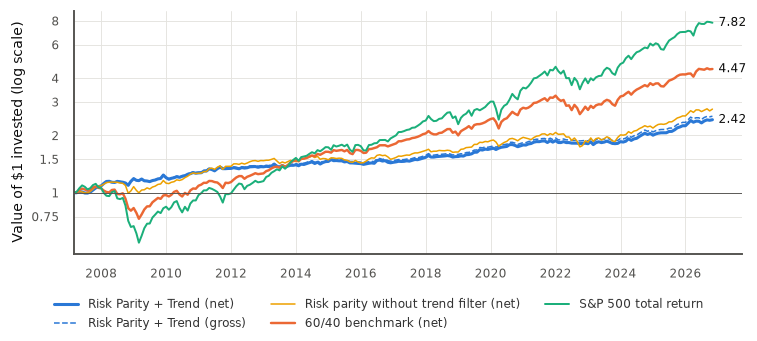

In [23]:
navs = {k: nav_from_returns(v) for k, v in series.items() if k != "1/N (no trend)"}
fig, ax = plt.subplots(figsize=(FIG_W, 3.0), layout="constrained")
style = {"Strategy": dict(color=COLORS["Strategy"], lw=2.0),
         "Strategy (gross)": dict(color=COLORS["Strategy"], lw=1.0, ls="--"),
         "ERC (no trend)": dict(color=COLORS["ERC (no trend)"], lw=1.0),
         "60/40": dict(color=COLORS["60/40"], lw=1.6),
         "S&P 500 TR": dict(color=COLORS["S&P 500 TR"], lw=1.3)}
labels = {"Strategy": "Risk Parity + Trend (net)", "Strategy (gross)": "Risk Parity + Trend (gross)",
          "ERC (no trend)": "Risk parity without trend filter (net)", "60/40": "60/40 benchmark (net)",
          "S&P 500 TR": "S&P 500 total return"}
for k, nav in navs.items():
    ax.plot(nav.index, nav, label=labels[k], **style[k])
for k in ["Strategy", "60/40", "S&P 500 TR"]:
    ax.annotate(f"{navs[k].iloc[-1]:.2f}", xy=(navs[k].index[-1], navs[k].iloc[-1]), xytext=(4, 0),
                textcoords="offset points", va="center", fontsize=8, color=INK)
ax.axhline(1, color=INK_2, lw=0.6)
ax.set_yscale("log")
ax.set_yticks([0.75, 1, 1.5, 2, 3, 4, 6, 8])
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}"))
ax.yaxis.set_minor_formatter(plt.NullFormatter())
ax.set_ylabel("Value of $1 invested (log scale)")
ax.set_xlim(navs["Strategy"].index[0], navs["Strategy"].index[-1] + pd.Timedelta(days=330))
legend_below(fig, ax, ncol=3)
save_figure(fig, "fig_cumulative")
plt.show()
register_item("fig_cumulative", r"Figure~\ref{fig:cumulative}", "Cumulative performance (Figure)", "6.2",
              RISKY_ASSETS + OTHER_TICKERS + [RF_TICKER])

<a id="sec-6-3"></a>
### 6.3 Drawdowns — the risk clients feel

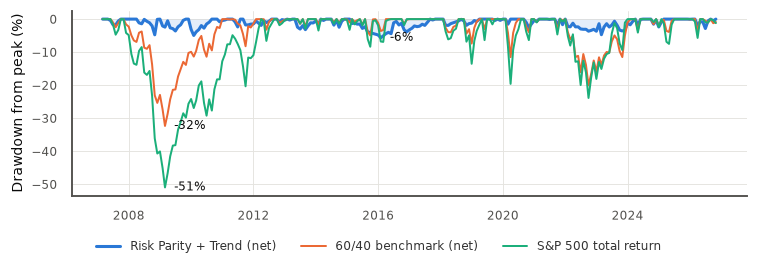

In [24]:
dds = {k: drawdown_series(series[k]) for k in ["Strategy", "60/40", "S&P 500 TR"]}
fig, ax = plt.subplots(figsize=(FIG_W, 2.3), layout="constrained")
for k, dd in dds.items():
    ax.plot(dd.index, 100 * dd, label=labels[k], color=COLORS[k], lw=2.0 if k == "Strategy" else 1.3)
ax.fill_between(dds["Strategy"].index, 100 * dds["Strategy"], 0, color=COLORS["Strategy"], alpha=0.12, lw=0)
for k in ["Strategy", "60/40", "S&P 500 TR"]:
    t_min = dds[k].idxmin()
    ax.annotate(f"{100 * dds[k].min():.0f}%", xy=(t_min, 100 * dds[k].min()), xytext=(6, -2),
                textcoords="offset points", fontsize=8, color=INK)
ax.set_ylabel("Drawdown from peak (%)")
legend_below(fig, ax, ncol=3)
save_figure(fig, "fig_drawdowns")
plt.show()
register_item("fig_drawdowns", r"Figure~\ref{fig:drawdowns}", "Drawdowns (Figure)", "6.3",
              RISKY_ASSETS + OTHER_TICKERS + [RF_TICKER])
for k, key in [("Strategy", "strat"), ("60/40", "b6040"), ("S&P 500 TR", "mkt")]:
    register(f"{key}_maxdd_date", dds[k].idxmin(), "date", f"{k}: month of the maximum drawdown", "6.3",
             RISKY_ASSETS if k == "Strategy" else ["SPY", "AGG", MARKET])

<a id="sec-6-4"></a>
### 6.4 Allocation over time

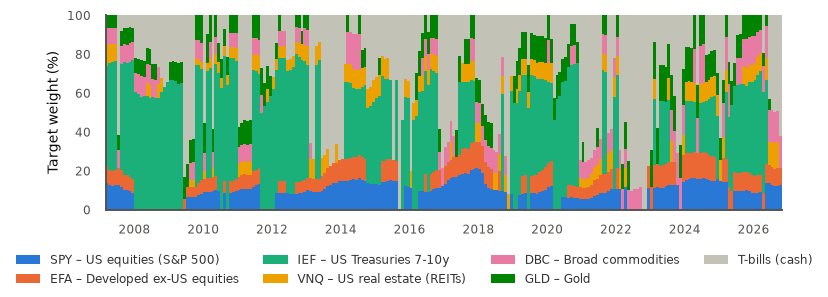

Average target weights:
SPY      9.1
EFA      6.4
IEF     33.1
VNQ      5.6
DBC      6.2
GLD      7.8
CASH    31.7
Share of months with a T-bill position: 81%


'33.1%'

In [25]:
W = base["weights"]
fig, ax = plt.subplots(figsize=(FIG_W, 2.6), layout="constrained")
cols = RISKY_ASSETS + ["CASH"]
bottom = np.zeros(len(W))
for c in cols:   # weights are held for one month -> step plot
    top = bottom + 100 * W[c].to_numpy()
    ax.fill_between(W.index, bottom, top, step="post", color=ASSET_COLORS[c], lw=0,
                    label=f"{c} – {ASSET_NAMES[c]}" if c != "CASH" else "T-bills (cash)")
    bottom = top
ax.set_ylim(0, 100)
ax.set_xlim(W.index[0], W.index[-1])
ax.set_ylabel("Target weight (%)")
ax.grid(False)
legend_below(fig, ax, ncol=4)
save_figure(fig, "fig_weights")
plt.show()
register_item("fig_weights", r"Figure~\ref{fig:weights}", "Target weights over time (Figure)", "6.4", RISKY_ASSETS)

avg_w = W.mean()
share_any_cash = (W["CASH"] > 1e-9).mean()
print("Average target weights:\n" + (100 * avg_w).round(1).to_string())
print(f"Share of months with a T-bill position: {share_any_cash:.0%}")
for c in cols:
    register(f"avg_w_{c.lower()}", avg_w[c], "pct1", f"Average target weight of {c}", "6.4", RISKY_ASSETS)
register("share_cash_months", share_any_cash, "pct1", "Share of months with a T-bill position", "6.4", RISKY_ASSETS)
register("max_cash", W["CASH"].max(), "pct1", "Highest T-bill weight in any month", "6.4", RISKY_ASSETS)
register("max_cash_date", W["CASH"].idxmax(), "date", "Month of the highest T-bill weight", "6.4", RISKY_ASSETS)
register("bond_share_avg", avg_w["IEF"], "pct1", "Average weight of Treasuries (IEF)", "6.4", RISKY_ASSETS)

<a id="sec-6-5"></a>
### 6.5 Calendar-year returns and rolling market exposure

In [26]:
def calendar_returns(r):
    return (1 + r).groupby(r.index.year).prod() - 1

cal = pd.DataFrame({k: calendar_returns(series[k]) for k in ["Strategy", "60/40", "S&P 500 TR"]})
cal.index.name = "year"
# note: 2007 (Mar-Dec) and 2026 (Jan-Oct) are partial years
display_cal = cal.style.format("{:.1%}")
for yr in [2008, 2020, 2022]:
    for k, key in [("Strategy", "strat"), ("60/40", "b6040"), ("S&P 500 TR", "mkt")]:
        register(f"{key}_ret_{yr}", cal.loc[yr, k], "pct1", f"{k}: return in calendar year {yr}", "6.5",
                 RISKY_ASSETS + [RF_TICKER] if k == "Strategy" else ["SPY", "AGG", MARKET])
register("years_beating_6040", int((cal["Strategy"] > cal["60/40"]).sum()), "int",
         "Calendar years in which the strategy beat 60/40", "6.5", RISKY_ASSETS + ["AGG"])
register("n_years_cal", len(cal), "int", "Calendar years (incl. partial 2007 and 2026)", "6.5", RISKY_ASSETS)
display_cal

,Strategy,60/40,S&P 500 TR
year,,,
2007,8.6%,5.4%,6.0%
2008,9.3%,-21.1%,-37.0%
2009,1.1%,16.9%,26.5%
2010,6.0%,12.0%,15.1%
2011,5.5%,4.5%,2.1%
2012,2.0%,11.1%,16.0%
2013,2.4%,17.5%,32.4%
2014,4.2%,10.5%,13.7%
2015,-2.6%,1.1%,1.4%


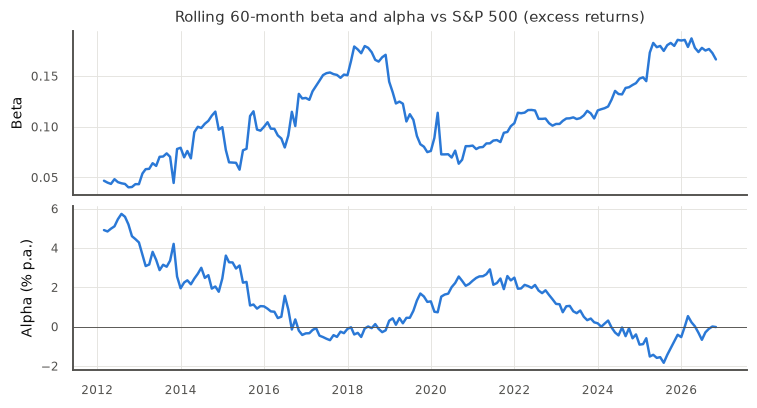

'0.19'

In [27]:
# Rolling 60-month beta and alpha vs the S&P 500 (quantstats, on excess returns as in Lecture 3)
greeks = qs.stats.rolling_greeks(r_strat - rf, benchmark=r_mkt - rf, periods=60, prepare_returns=False)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(FIG_W, 3.6), sharex=True, layout="constrained")
ax1.plot(greeks.index, greeks["beta"], color=COLORS["Strategy"])
ax1.set_ylabel("Beta")
ax1.set_title("Rolling 60-month beta and alpha vs S&P 500 (excess returns)")
ax2.plot(greeks.index, 1200 * greeks["alpha"], color=COLORS["Strategy"])
ax2.axhline(0, color=INK_2, lw=0.6)
ax2.set_ylabel("Alpha (% p.a.)")
plt.show()
register("roll_beta_min", greeks["beta"].min(), "num2", "Lowest rolling 60-month beta", "6.5", RISKY_ASSETS + [MARKET])
register("roll_beta_max", greeks["beta"].max(), "num2", "Highest rolling 60-month beta", "6.5", RISKY_ASSETS + [MARKET])

<a id="sec-6-6"></a>
### 6.6 quantstats report (display only)

The full quantstats metrics report for the strategy against the 60/40 benchmark (net returns, as in
Lecture 3). quantstats uses its own conventions here: risk-free rate 0, calendar-based compounding.
Its Sharpe ratio is therefore **not** the one in our table, which subtracts the T-bill rate.
Section 7 reconciles the two.

In [28]:
qs.reports.metrics(r_strat, benchmark=r_6040, periods_per_year=PERIODS, prepare_returns=False, mode="basic")


Parameter       Value
--------------  ---------
Benchmark       Benchmark
Risk-Free Rate  0.0%
Periods/Year    12
Compounded      Yes
Match Dates     Yes


                     Benchmark    Strategy
-------------------  -----------  ----------
Start Period         2007-03-31   2007-03-31
End Period           2026-10-31   2026-10-31
Risk-Free Rate       0.0%         0.0%
Time in Market       100.0%       100.0%

Cumulative Return    346.74%      141.86%
CAGR﹪               7.91%        4.59%

Sharpe               0.82         0.98
Prob. Sharpe Ratio   99.96%       100.0%
Sortino              1.27         1.75
Sortino/√2           0.9          1.23
Omega                1.84         2.06

Max Drawdown         -32.34%      -5.65%
Max DD Date          2009-02-28   2016-01-31
Max DD Period Start  2007-11-30   2015-02-28
Max DD Period End    2010-11-30   2017-07-31
Longest DD Days      1097         885

Gain/Pain Ratio      0.84         1.06
Gain/Pain (1M)       0.84         1.06

Payoff Rat

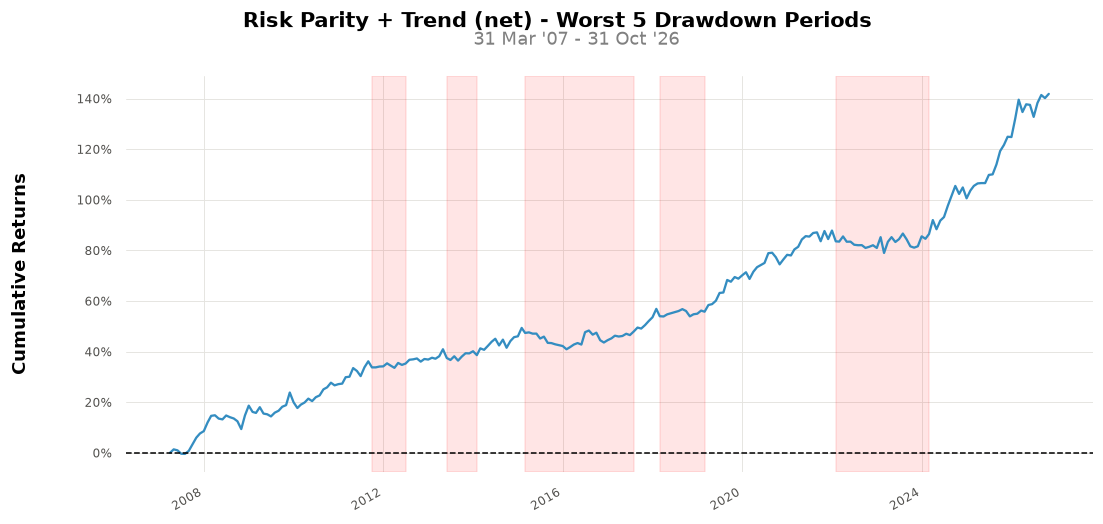

In [29]:
qs.plots.drawdowns_periods(r_strat, fontname="DejaVu Sans", title="Risk Parity + Trend (net)")

<a id="sec-7"></a>
## 7 Verification

A backtest is only as good as its checks (Lecture 4: *specify, generate, verify*). Every assertion
below must pass for the notebook to finish.

In [30]:
checks = []

def check(name, condition):
    checks.append((name, bool(condition)))
    assert condition, name

# 1. weights are valid portfolios
check("weights sum to 1 every month", np.allclose(W.sum(axis=1), 1.0, atol=1e-12))
check("no short positions", (W >= -1e-12).all().all())
check("fsolve converged in every month (0 fallbacks)", base["fsolve_fallbacks"] == 0)

# 2. equal risk contributions before the trend filter, every month
px_all = data.prices_d[RISKY_ASSETS].dropna()
rd_all = px_all.pct_change(fill_method=None).iloc[1:]
rc_dev = []
for t in DECISION_DATES:
    c = np.cov(rd_all.loc[:t].iloc[-COV_WINDOW:].to_numpy(), rowvar=False)
    w_t, _ = erc_weights(c)
    rc_dev.append(np.max(np.abs(risk_contributions(w_t, c) - 1 / len(RISKY_ASSETS))))
check("risk contributions equal within 1e-8 in every month", max(rc_dev) < 1e-8)
print(f"largest deviation of a risk contribution from 1/N: {max(rc_dev):.1e}")

# 3. no look-ahead: weights up to Dec 2015 are identical when the data end in Dec 2015
data_trunc = build_market_data(prices_raw.loc[:"2015-12-31"], RISKY_ASSETS, OTHER_TICKERS, RF_TICKER)
dates_trunc = DECISION_DATES[DECISION_DATES <= "2015-12-31"]
W_trunc = target_weights(data_trunc, RISKY_ASSETS, dates_trunc, COV_WINDOW, SMA_WINDOW, True, WEIGHTING)
check("truncation test: weights unchanged when future data are removed",
      np.allclose(W_trunc.to_numpy(), W.loc[dates_trunc].to_numpy(), atol=1e-12))

# 4. engine identities
res = base["result"]
check("net = (1 - cost) x (1 + gross) - 1", np.allclose(1 + res["net"], (1 - res["cost"]) * (1 + res["gross"])))
zero = run_strategy(data, RISKY_ASSETS, COV_WINDOW, SMA_WINDOW, True, WEIGHTING, 0.0, T0,
                    benchmark_weights=BENCHMARK_6040)
closed_6040 = 0.6 * data.rets_m["SPY"] + 0.4 * data.rets_m["AGG"]
check("60/40 from the engine (zero cost) = 0.6 R_SPY + 0.4 R_AGG",
      np.allclose(zero["benchmark"], closed_6040.loc[RETURN_MONTHS], atol=1e-14))
check("NAV starts at 1 on the first decision date", navs["Strategy"].iloc[0] == 1.0
      and navs["Strategy"].index[0] == T0)

# 5. OLS beta = moment beta (cov/var) and alpha = E[R-Rf] - beta E[Rm-Rf]  (Lecture 3 formulas)
ex, mex = r_strat - rf, r_mkt - rf
beta_mom = np.cov(ex, mex, ddof=1)[0, 1] / np.var(mex, ddof=1)
alpha_mom = 12 * (ex.mean() - beta_mom * mex.mean())
check("regression beta = cov/var", np.isclose(beta_mom, P["beta_mkt"]))
check("regression alpha = E[R-Rf] - beta E[Rm-Rf]", np.isclose(alpha_mom, P["alpha_mkt"]))

# 6. quantstats cross-checks (feed excess returns; quantstats' IR is monthly -> x sqrt(12))
qs_vol = qs.stats.volatility(r_strat, periods=12, prepare_returns=False)
qs_sr = qs.stats.sharpe(ex, periods=12)
qs_greeks = qs.stats.greeks(ex, mex, periods=12, prepare_returns=False)
qs_ir = qs.stats.information_ratio(r_strat, r_6040, prepare_returns=False) * np.sqrt(12)
qs_cagr = qs.stats.cagr(r_strat, periods=12)
qs_mdd = qs.stats.max_drawdown(r_strat)
check("quantstats volatility", np.isclose(qs_vol, P["ann_vol"]))
check("quantstats Sharpe on excess returns", np.isclose(qs_sr, P["sharpe"]))
check("quantstats beta", np.isclose(qs_greeks["beta"], P["beta_mkt"]))
check("quantstats alpha on excess returns", np.isclose(qs_greeks["alpha"], P["alpha_mkt"]))
check("quantstats information ratio x sqrt(12)", np.isclose(qs_ir, P["info_ratio"]))
print(f"CAGR: ours {P['cagr']:.4%} vs quantstats {qs_cagr:.4%}")
print(f"Max drawdown: ours {P['max_dd']:.4%} vs quantstats {qs_mdd:.4%}")
check("quantstats CAGR (12 periods per year)", np.isclose(qs_cagr, P["cagr"], atol=1e-4))
check("quantstats max drawdown", np.isclose(qs_mdd, P["max_dd"], atol=1e-4))

# 7. data sanity: SPY tracks the S&P 500 total return index
rho = data.rets_m["SPY"].corr(data.rets_m[MARKET])
gap = 12 * (data.rets_m[MARKET] - data.rets_m["SPY"]).loc[RETURN_MONTHS].mean()
check("SPY vs ^SP500TR correlation > 0.999", rho > 0.999)
print(f"SPY vs S&P 500 TR: correlation {rho:.5f}, average return gap {gap:.2%} p.a. (fund costs)")
register("spy_index_gap", gap, "pct2", "Average return gap S&P 500 TR minus SPY p.a.", "7", ["SPY", MARKET])

pd.DataFrame(checks, columns=["check", "passed"])

largest deviation of a risk contribution from 1/N: 4.6e-14


CAGR: ours 4.5931% vs quantstats 4.5931%
Max drawdown: ours -5.6548% vs quantstats -5.6548%
SPY vs S&P 500 TR: correlation 0.99959, average return gap 0.09% p.a. (fund costs)


,check,passed
0,weights sum to 1 every month,True
1,no short positions,True
2,fsolve converged in every month (0 fallbacks),True
3,risk contributions equal within 1e-8 in every ...,True
4,truncation test: weights unchanged when future...,True
5,net = (1 - cost) x (1 + gross) - 1,True
6,60/40 from the engine (zero cost) = 0.6 R_SPY ...,True
7,NAV starts at 1 on the first decision date,True
8,regression beta = cov/var,True
9,regression alpha = E[R-Rf] - beta E[Rm-Rf],True


<a id="sec-8"></a>
## 8 Robustness

<a id="sec-8-1"></a>
### 8.1 Transaction costs and the break-even cost (fsolve)

Costs are charged on turnover. We vary them from 0 to 50 bps per unit traded. The **break-even
cost** is the cost level at which the strategy's Sharpe ratio falls to that of the 60/40
benchmark, with the same cost applied to both. It solves
$SR_{\text{strategy}}(c)-SR_{60/40}(c)=0$ with **`fsolve`**. If the strategy is not ahead even at
zero cost, no break-even exists.

In [31]:
W_bench = constant_weights(BENCHMARK_6040, DECISION_DATES)


def sharpe_at(weights, c):
    r = backtest(weights, data, c)["net"]
    return performance_summary(r, data.rf_m)["sharpe"]


cost_grid = [0, 5, 10, 20, 30, 50]
cost_rows = []
for c in cost_grid:
    rs = backtest(W, data, c)["net"]
    rb = backtest(W_bench, data, c)["net"]
    ps, pb = performance_summary(rs, data.rf_m), performance_summary(rb, data.rf_m)
    cost_rows.append({"cost (bps)": c, "strategy CAGR": ps["cagr"], "strategy Sharpe": ps["sharpe"],
                      "60/40 CAGR": pb["cagr"], "60/40 Sharpe": pb["sharpe"]})
cost_df = pd.DataFrame(cost_rows).set_index("cost (bps)")

c_star, has_star = breakeven_cost(lambda c: sharpe_at(W, c) - sharpe_at(W_bench, c), x0=COST_BPS)
print(f"Break-even cost (Sharpe): {c_star:.1f} bps" if has_star else
      "No break-even: the strategy's Sharpe ratio is below the 60/40 Sharpe ratio even at zero cost")
annual_drag = P["turnover"] * COST_BPS / 1e4
print(f"Cost drag at {COST_BPS:.0f} bps: {annual_drag:.2%} p.a. (turnover {P['turnover']:.0%} p.a.)")
register("cost_drag", annual_drag, "pct2", f"Annual cost drag at {COST_BPS:.0f} bps", "8.1", RISKY_ASSETS)
register("cost_bps", COST_BPS, "bps0", "Assumed trading cost per unit of turnover", "0.2", [])
register("breakeven_bps", c_star if has_star else "none", "bps0" if has_star else "text",
         "Break-even cost at which Sharpe equals 60/40", "8.1", RISKY_ASSETS + ["AGG", RF_TICKER])
register("sharpe_cost50", cost_df.loc[50, "strategy Sharpe"], "num2", "Strategy Sharpe ratio at 50 bps", "8.1",
         RISKY_ASSETS + [RF_TICKER])
register("cagr_cost50", cost_df.loc[50, "strategy CAGR"], "pct1", "Strategy CAGR at 50 bps", "8.1", RISKY_ASSETS)
cost_df.style.format({"strategy CAGR": "{:.2%}", "60/40 CAGR": "{:.2%}", "strategy Sharpe": "{:.2f}",
                      "60/40 Sharpe": "{:.2f}"})

Break-even cost (Sharpe): 7.6 bps
Cost drag at 10 bps: 0.22% p.a. (turnover 216% p.a.)


,strategy CAGR,strategy Sharpe,60/40 CAGR,60/40 Sharpe
cost (bps),,,,
0,4.82%,0.71,7.93%,0.67
5,4.71%,0.68,7.92%,0.67
10,4.59%,0.66,7.91%,0.67
20,4.37%,0.61,7.88%,0.67
30,4.14%,0.56,7.86%,0.66
50,3.69%,0.47,7.80%,0.66


<a id="sec-8-2"></a>
### 8.2 Stress periods

In [32]:
PERIODS_STRESS = {
    "Financial crisis": ("2007-11-30", "2009-02-28"),
    "Covid crash": ("2020-02-29", "2020-03-31"),
    "Inflation and rate shock": ("2022-01-31", "2022-10-31"),
    "Recovery": ("2023-01-31", "2026-10-31"),
}
stress_rows = {}
for label, (a, b) in PERIODS_STRESS.items():
    row = {}
    for k in ["Strategy", "60/40", "S&P 500 TR"]:
        r = series[k].loc[a:b]
        row[k] = np.prod(1 + r) - 1
    stress_rows[f"{label} ({pd.Timestamp(a):%b %Y}–{pd.Timestamp(b):%b %Y})"] = row
stress = pd.DataFrame(stress_rows).T
key_map = {"Financial crisis": "gfc", "Covid crash": "covid", "Inflation and rate shock": "infl",
           "Recovery": "recov"}
for (label, _), short in zip(PERIODS_STRESS.items(), key_map.values()):
    full = next(i for i in stress.index if i.startswith(label))
    for k, key in [("Strategy", "strat"), ("60/40", "b6040"), ("S&P 500 TR", "mkt")]:
        register(f"{key}_{short}", stress.loc[full, k], "pct1", f"{k}: return, {full}", "8.2",
                 RISKY_ASSETS + [RF_TICKER] if k == "Strategy" else ["SPY", "AGG", MARKET])
stress.style.format("{:.1%}")

,Strategy,60/40,S&P 500 TR
Financial crisis (Nov 2007–Feb 2009),9.2%,-32.3%,-50.9%
Covid crash (Feb 2020–Mar 2020),0.1%,-11.5%,-19.6%
Inflation and rate shock (Jan 2022–Oct 2022),-3.4%,-16.6%,-17.7%
Recovery (Jan 2023–Oct 2026),33.6%,64.0%,108.0%


<a id="sec-8-3"></a>
### 8.3 Parameter sensitivity

The base case uses a 10-month moving average and a 252-day risk window. Both are fixed in advance
(Faber, 2007; a standard one-year estimate). A robust rule should show a *plateau* of similar
Sharpe ratios around the base case, not a single spike. All runs use the same months.

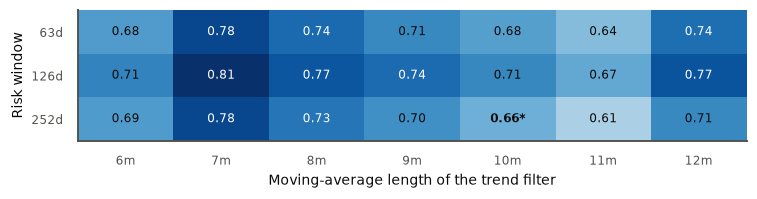

SMA (months),6,7,8,9,10,11,12
risk window (days),,,,,,,
63,0.68,0.78,0.74,0.71,0.68,0.64,0.74
126,0.71,0.81,0.77,0.74,0.71,0.67,0.77
252,0.69,0.78,0.73,0.70,0.66,0.61,0.71


In [33]:
SMA_GRID = [6, 7, 8, 9, 10, 11, 12]
COV_GRID = [63, 126, 252]
heat = pd.DataFrame(index=COV_GRID, columns=SMA_GRID, dtype=float)
for cw in COV_GRID:
    for sm_ in SMA_GRID:
        run = run_strategy(data, RISKY_ASSETS, cw, sm_, True, WEIGHTING, COST_BPS, T0)
        heat.loc[cw, sm_] = performance_summary(run["returns"], data.rf_m)["sharpe"]
heat.index.name, heat.columns.name = "risk window (days)", "SMA (months)"

fig, ax = plt.subplots(figsize=(FIG_W, 1.7), layout="constrained")
im = ax.imshow(heat.to_numpy(), cmap="Blues", aspect="auto", vmin=heat.min().min() - 0.1, vmax=heat.max().max())
ax.set_xticks(range(len(SMA_GRID)), [f"{s}m" for s in SMA_GRID])
ax.set_yticks(range(len(COV_GRID)), [f"{c}d" for c in COV_GRID])
ax.set_xlabel("Moving-average length of the trend filter")
ax.set_ylabel("Risk window")
ax.grid(False)
for i in range(len(COV_GRID)):
    for j in range(len(SMA_GRID)):
        v = heat.iloc[i, j]
        is_base = COV_GRID[i] == COV_WINDOW and SMA_GRID[j] == SMA_WINDOW
        ax.text(j, i, f"{v:.2f}" + ("*" if is_base else ""), ha="center", va="center", fontsize=8,
                color="white" if v > heat.to_numpy().mean() else INK, fontweight="bold" if is_base else "normal")
save_figure(fig, "fig_sensitivity")
plt.show()
register_item("fig_sensitivity", r"Figure~\ref{fig:sensitivity}", "Parameter sensitivity of the Sharpe ratio (Figure)",
              "8.3", RISKY_ASSETS + [RF_TICKER])
register("heat_min", heat.min().min(), "num2", "Lowest Sharpe ratio in the parameter grid", "8.3", RISKY_ASSETS)
register("heat_max", heat.max().max(), "num2", "Highest Sharpe ratio in the parameter grid", "8.3", RISKY_ASSETS)
register("heat_n", heat.size, "int", "Number of parameter combinations tested", "8.3", RISKY_ASSETS)
heat.style.format("{:.2f}")

<a id="sec-8-4"></a>
### 8.4 Leave-one-out: does the result depend on one asset class?

We chose the universe of asset classes before looking at results. Even so, an asset with an
exceptional run (for example gold in 2024–2026) could drive the result. We therefore rerun the
strategy six times, each time without one asset class, over the same months and with the same costs.

In [34]:
loo_rows = {"All six (base case)": performance_summary(r_strat, data.rf_m)}
for a in RISKY_ASSETS:
    keep = [x for x in RISKY_ASSETS if x != a]
    run = run_strategy(data, keep, COV_WINDOW, SMA_WINDOW, True, WEIGHTING, COST_BPS, T0)
    loo_rows[f"without {a}"] = performance_summary(run["returns"], data.rf_m)
loo = pd.DataFrame(loo_rows).T[["cagr", "ann_vol", "sharpe", "max_dd"]]
worst = loo["sharpe"].drop("All six (base case)").idxmin()
register("loo_sharpe_min", loo["sharpe"].drop("All six (base case)").min(), "num2",
         "Lowest Sharpe ratio when one asset class is left out", "8.4", RISKY_ASSETS + [RF_TICKER])
register("loo_sharpe_max", loo["sharpe"].drop("All six (base case)").max(), "num2",
         "Highest Sharpe ratio when one asset class is left out", "8.4", RISKY_ASSETS + [RF_TICKER])
register("loo_worst_asset", worst.replace("without ", ""), "text",
         "Asset class whose removal lowers the Sharpe ratio most", "8.4", RISKY_ASSETS)
register("loo_sharpe_nogold", loo.loc["without GLD", "sharpe"], "num2", "Sharpe ratio without gold", "8.4",
         RISKY_ASSETS + [RF_TICKER])
register("loo_maxdd_worst", loo["max_dd"].drop("All six (base case)").min(), "pct1",
         "Deepest drawdown when one asset class is left out", "8.4", RISKY_ASSETS)

rows_tex = [(tex_escape(i), [tex_num(loo.loc[i, "cagr"], "pct"), tex_num(loo.loc[i, "ann_vol"], "pct"),
                             tex_num(loo.loc[i, "sharpe"], "num"), tex_num(loo.loc[i, "max_dd"], "pct")])
            for i in loo.index]
save_table(fin_table([("", rows_tex)], [r"CAGR (\%)", r"Vol.\ (\%)", "Sharpe", r"Max DD (\%)"],
                     first_col="Universe"), "tab_leave_one_out")
register_item("tab_leave_one_out", r"Table~\ref{tab:loo}", "Leave-one-out robustness (Table)", "8.4",
              RISKY_ASSETS + [RF_TICKER])
loo.style.format({"cagr": "{:.1%}", "ann_vol": "{:.1%}", "sharpe": "{:.2f}", "max_dd": "{:.1%}"})

,cagr,ann_vol,sharpe,max_dd
All six (base case),4.6%,4.7%,0.66,-5.7%
without SPY,4.0%,4.9%,0.53,-6.3%
without EFA,4.6%,4.8%,0.66,-6.1%
without IEF,6.3%,7.8%,0.63,-14.1%
without VNQ,4.9%,4.5%,0.75,-5.2%
without DBC,4.7%,5.2%,0.63,-7.7%
without GLD,4.0%,4.4%,0.56,-5.7%


<a id="sec-9"></a>
## 9 Number register and export

The register lists every number, table and figure used in the prospectus with its description, the
notebook section that computes it, the data source and the retrieval time. A local run writes:
* `prospectus/results_macros.tex` – one `\defres{...}` line per entry (read by `resultref.sty`),
* `prospectus/figures/*.pdf`, `prospectus/tables/*.tex` – figures and tables of the prospectus,
* `results/results.json` – the headline numbers, used by the app's consistency test.

In [35]:
def source_text(tickers):
    tickers = list(dict.fromkeys(tickers))
    if not tickers:
        return "Model assumption"
    if set(tickers) >= set(ALL_TICKERS):
        return "YF: all 9 series"
    if set(RISKY_ASSETS) <= set(tickers):     # abbreviate the six strategy ETFs
        tickers = ["6 ETFs"] + [t for t in tickers if t not in RISKY_ASSETS]
    return "YF: " + ", ".join(tickers)


reg_df = pd.DataFrame([{"key": e["key"], "value": e["value"], "description": e["description"],
                        "notebook section": "§" + e["section"], "source": source_text(e["sources"]),
                        "retrieved": RETRIEVED_TXT if e["sources"] else "–"} for e in REGISTER])
print(f"{len(reg_df)} registered results")
reg_df

125 registered results


,key,value,description,notebook section,source,retrieved
0,data_retrieved,2026-11-20 22:11 UTC,Time stamp of the Yahoo Finance download,§1,YF: all 9 series,2026-11-20 22:11 UTC
1,data_start,01 Jan 2006,First day of daily data requested,§0.2,YF: all 9 series,2026-11-20 22:11 UTC
2,data_end,30 Oct 2026,Last trading day in the sample,§2,YF: all 9 series,2026-11-20 22:11 UTC
3,first_decision,28 Feb 2007,First rebalancing date (decision at the close),§3,YF: 6 ETFs,2026-11-20 22:11 UTC
4,sample_start,Mar 2007,First month with a strategy return,§3,YF: 6 ETFs,2026-11-20 22:11 UTC
...,...,...,...,...,...,...
120,loo_sharpe_max,0.75,Highest Sharpe ratio when one asset class is l...,§8.4,"YF: 6 ETFs, ^IRX",2026-11-20 22:11 UTC
121,loo_worst_asset,SPY,Asset class whose removal lowers the Sharpe ra...,§8.4,YF: 6 ETFs,2026-11-20 22:11 UTC
122,loo_sharpe_nogold,0.56,Sharpe ratio without gold,§8.4,"YF: 6 ETFs, ^IRX",2026-11-20 22:11 UTC
123,loo_maxdd_worst,-14.1%,Deepest drawdown when one asset class is left out,§8.4,YF: 6 ETFs,2026-11-20 22:11 UTC


In [36]:
if EXPORT:
    lines = ["% AUTO-GENERATED by notebook/GroupZ_RiskParity_Trend.ipynb (Section 9). Do not edit.",
             f"% Data retrieved from Yahoo Finance via yfinance: {RETRIEVED_TXT}",
             r"% \defres{key}{value}{description}{notebook section}{link}{source}{retrieved}"]
    for e in REGISTER:
        anchor = "sec-" + e["section"].replace(".", "-")
        link = NOTEBOOK_VIEW_URL + r"\#" + anchor
        retrieved = DATA_RETRIEVED_UTC.strftime("%Y-%m-%d") if e["sources"] else "--"
        lines.append(rf"\defres{{{e['key']}}}{{{e['tex']}}}{{{tex_escape(e['description'])}}}"
                     rf"{{\S{e['section']}}}{{{link}}}{{{tex_escape(source_text(e['sources']))}}}{{{retrieved}}}")
    (REPO_ROOT / "prospectus" / "results_macros.tex").write_text("\n".join(lines) + "\n", encoding="utf-8")

    results = {"retrieved_utc": RETRIEVED_TXT, "start": START, "end": END, "first_decision": str(T0.date()),
               "params": {"cov_window": COV_WINDOW, "sma_window": SMA_WINDOW, "cost_bps": COST_BPS,
                          "weighting": WEIGHTING},
               "strategy": {k: float(v) for k, v in P.items()},
               "benchmark_6040": {k: float(v) for k, v in B.items()}}
    (REPO_ROOT / "results").mkdir(exist_ok=True)
    (REPO_ROOT / "results" / "results.json").write_text(json.dumps(results, indent=2), encoding="utf-8")
    print("exported:", sorted(p.name for p in FIG_DIR.iterdir()), sorted(p.name for p in TAB_DIR.iterdir()))
else:
    print("Not exporting (Colab or outside the repository) - all results are shown above.")

exported: ['fig_cumulative.pdf', 'fig_drawdowns.pdf', 'fig_sensitivity.pdf', 'fig_weights.pdf'] ['tab_leave_one_out.tex', 'tab_performance.tex']


<a id="sec-10"></a>
## 10 Extension (placeholder): machine-learning overlay

The core strategy is deliberately rule-based and interpretable. This section is reserved for a
possible machine-learning extension, for example a walk-forward-trained regime classifier that
replaces the moving-average trend filter. Any extension must meet the same standards as the core:
* it uses only information available at each decision date,
* it is evaluated over the same months,
* it reports results net of costs.